# 02 · Measuring the variance risk premium (Tier 1)

**Owner: Nahid**

**Question:** is implied variance (VIX²) higher than the variance that actually follows, on average? If it is, how large is the premium, is it statistically significant, and what do its losses look like?

`vrp` = VIX²/10000 − realized variance over the next 21 trading days. It is the P&L of a short variance swap per unit notional.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import load_daily, EPISODES, episode_mask
df = load_daily('../data/daily.csv')
df.tail()

,spx_open,spx_high,spx_low,spx_close,vix,vix3m,rf,logret,iv_var,rv_d,rv_w,rv_m,rv_parkinson_d,rv_fwd21,vrp,vrp_volpts,vix_ratio
date,,,,,,,,,,,,,,,,,
2026-10-29,7699.609863,7732.209961,7690.939941,7720.390137,17.200001,19.370001,0.0400,-0.003051,0.029584,0.002346,0.006430,0.009423,0.002603,NaN,NaN,NaN,0.887971
2026-10-30,7631.069824,7637.479980,7527.560059,7580.069824,19.420000,20.780001,0.0399,-0.018342,0.037714,0.084785,0.022024,0.013415,0.019101,NaN,NaN,NaN,0.934552
2026-11-02,7610.830078,7662.229980,7539.379883,7541.399902,21.150000,21.600000,0.0403,-0.005115,0.044732,0.006592,0.020915,0.013088,0.023745,NaN,NaN,NaN,0.979167
2026-11-03,7552.919922,7594.609863,7545.390137,7568.919922,20.830000,21.270000,0.0403,0.003643,0.043389,0.003344,0.019798,0.012722,0.003842,NaN,NaN,NaN,0.979314
2026-11-04,7635.810059,7715.569824,7635.810059,7688.620117,16.610001,18.799999,0.0403,0.015691,0.027589,0.062044,0.031822,0.015277,0.009814,NaN,NaN,NaN,0.883511


## 1. Plot
Two panels: (a) VIX² and RV together, (b) `vrp` over time. Shade `EPISODES`.

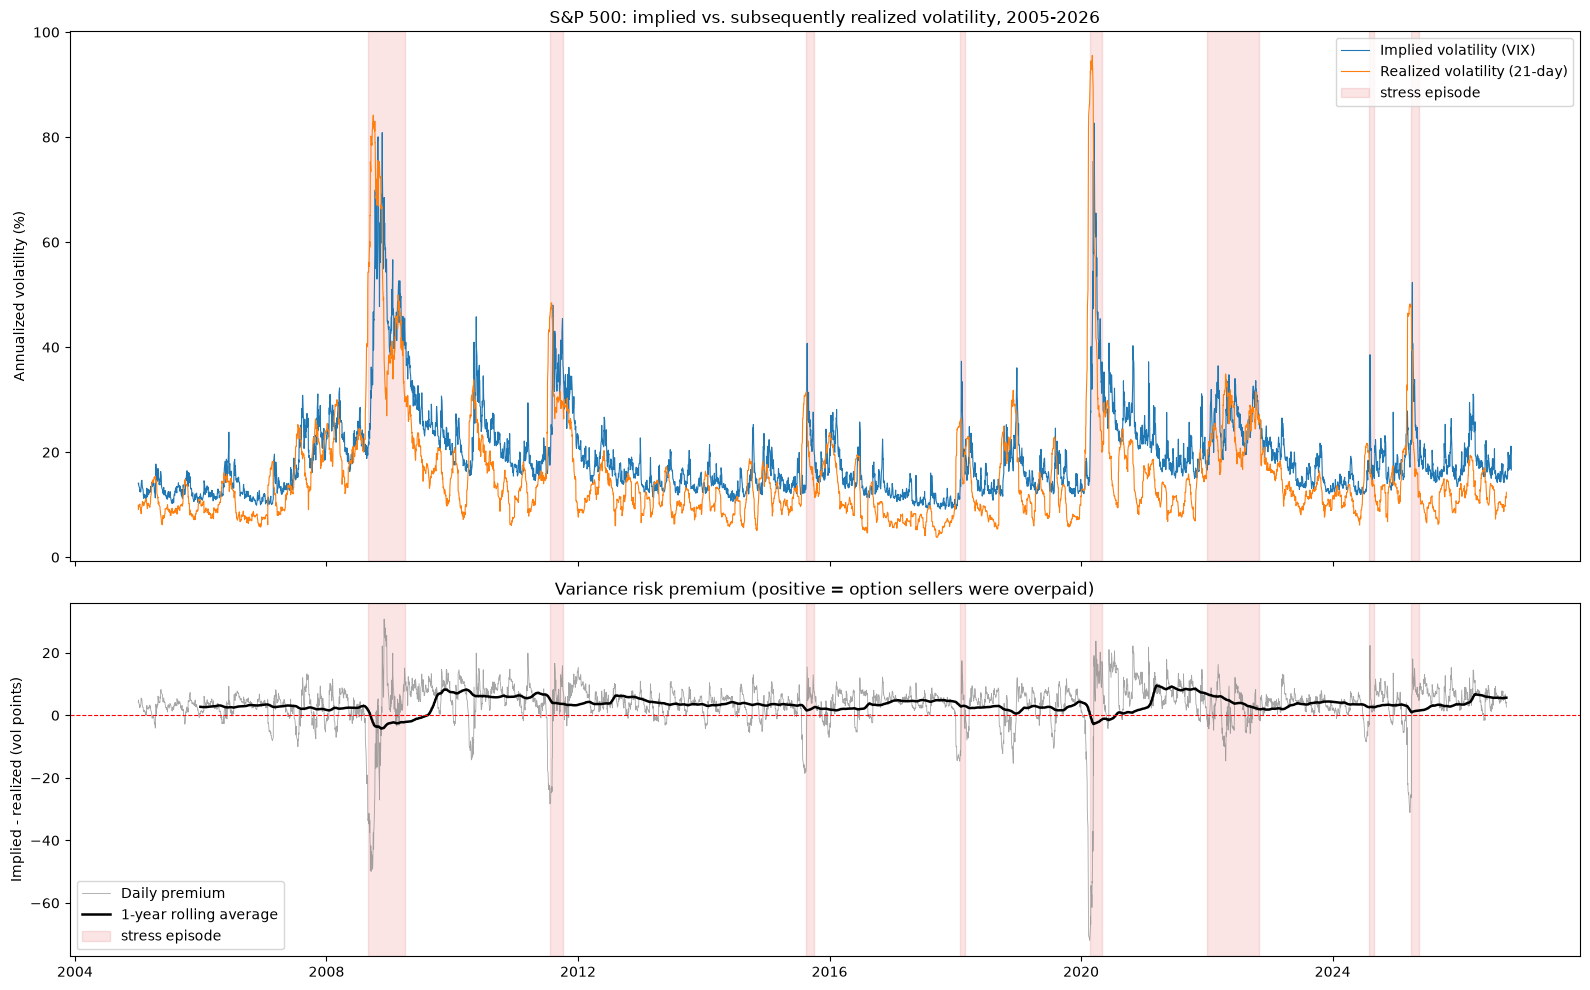

Share of days with implied > realized: 83.7%
Worst day: 2020-02-20 at -72.0 volatility points


In [2]:
import os
os.makedirs('../docs/figures', exist_ok=True)

impl_vol = 100 * np.sqrt(df["iv_var"]) # VIX, in volatility points
real_vol = 100 * np.sqrt(df["rv_fwd21"]) # realized volatility, in volatility points over the next 21 days
vrp_pts = df["vrp_volpts"] # implied minus realized volatility, in volatility points

fig, (ax1, ax2) = plt.subplots(2, 1, sharex = True, figsize = (16, 10), gridspec_kw = {"height_ratios": [3, 2]})

# (a) implied vs realized volatility
ax1.plot(impl_vol.index, impl_vol, lw = 0.8, color = "tab:blue", label = "Implied volatility (VIX)")
ax1.plot(real_vol.index, real_vol, lw = 0.8, color = "tab:orange", label = "Realized volatility (21-day)")
ax1.set_ylabel("Annualized volatility (%)")
ax1.set_title("S&P 500: implied vs. subsequently realized volatility, 2005-2026")

# the premium
ax2.plot(vrp_pts.index, vrp_pts, lw = 0.6, color = "grey", alpha = 0.7, label = "Daily premium")
ax2.plot(vrp_pts.index, vrp_pts.rolling(252).mean(), lw = 1.8, color = "black", label = "1-year rolling average")
ax2.axhline(0, color = "red", lw = 0.8, ls = "--")
ax2.set_ylabel("Implied - realized (vol points)")
ax2.set_title("Variance risk premium (positive = option sellers were overpaid)")

# shade crisis episodes on both panels, labelling each once
for ax in (ax1, ax2):
    for i, (name, (s, e)) in enumerate(EPISODES.items()):
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color = "tab:red", alpha = 0.12, label = "stress episode" if i == 0 else None)
ax1.legend(loc = "upper right")
ax2.legend(loc = "lower left")

plt.tight_layout()
plt.savefig("../docs/figures/fig1_implied_vs_realized_volatility.png", dpi = 150)
plt.show()

print(f"Share of days with implied > realized: {(vrp_pts.dropna() > 0).mean():.1%}")
print(f"Worst day: {vrp_pts.idxmin().date()} at {vrp_pts.min():.1f} volatility points")

## 2. Is the average premium positive?

**(a) Overlapping daily data with Newey–West errors.** Neighbouring days share 20 of 21 returns, so plain standard errors are far too small.

Hint: `import statsmodels.api as sm`, then `sm.OLS(y, np.ones(len(y))).fit(cov_type='HAC', cov_kwds={'maxlags': 21})`. Try maxlags 21, 30 and 42, and report whether the conclusion changes.

**(b) Non-overlapping months.** Take every 21st row (`y.iloc[::21]`) and run a plain one-sample t-test (`scipy.stats.ttest_1samp`).

In [3]:
y = df['vrp'].dropna()

import statsmodels.api as sm
from scipy import stats

X = pd.Series(1.0, index = y.index, name = 'const')
plain = sm.OLS(y, X).fit()
print(f"plain : mean = {plain.params['const']:.5f} se = {plain.bse['const']:.5f} t. = {plain.tvalues['const']:.2f}")
for L in [21, 30, 42]:
    nw = sm.OLS(y, X).fit(cov_type = "HAC", cov_kwds = {"maxlags": L})
    print(f"NW L = {L}: mean = {nw.params['const']:.5f} se = {nw.bse['const']:.5f} t. = {nw.tvalues['const']:.2f}")
print(f" mean permium in volatility points: {df['vrp_volpts'].mean():.2f}")

plain : mean = 0.00765 se = 0.00086 t. = 8.94
NW L = 21: mean = 0.00765 se = 0.00331 t. = 2.31
NW L = 30: mean = 0.00765 se = 0.00355 t. = 2.15
NW L = 42: mean = 0.00765 se = 0.00371 t. = 2.06
 mean permium in volatility points: 3.47


In [4]:
monthly = y.iloc[::21] # monthly sample
t, p = stats.ttest_1samp(monthly, 0)
print(f"non-overlapping: n = {len(monthly)} mean = {monthly.mean():.5f} t = {t:.2f} p = {p:.4f}")

# robustness: every possitlbe starting day
ts = [stats.ttest_1samp(y.iloc[k::21], 0).statistic for k in range(21)]
print(f"t-stat across 21 start offsets: min = {min(ts):.2f}, max = {max(ts):.2f}")

non-overlapping: n = 261 mean = 0.00629 t = 1.73 p = 0.0845
t-stat across 21 start offsets: min = 1.64, max = 2.55


## 3. Shape of the payoff
Mean, median, share of months positive, skewness, kurtosis, 5% CVaR (mean of the worst 5% of months) and the 5 worst months, all on the non-overlapping sample. Add a histogram.

Expected story: small gains most months, rare very large losses.

months             261.0000
mean                 0.0063
median               0.0109
share positive       0.8238
skewness            -5.3958
excess kurtosis     41.7462
5% CVaR             -0.1633
worst month         -0.5058
best month           0.2406
dtype: float64


5 worst months (entry date):
date
2020-03-11   -0.5058
2008-10-03   -0.4612
2008-11-03   -0.2800
2008-09-04   -0.2486
2020-02-10   -0.2360
Name: vrp, dtype: float64

Sign test: 215/261 months positive, p = 2.68e-27
Normality test (D'Agostino): p = 3.55e-70


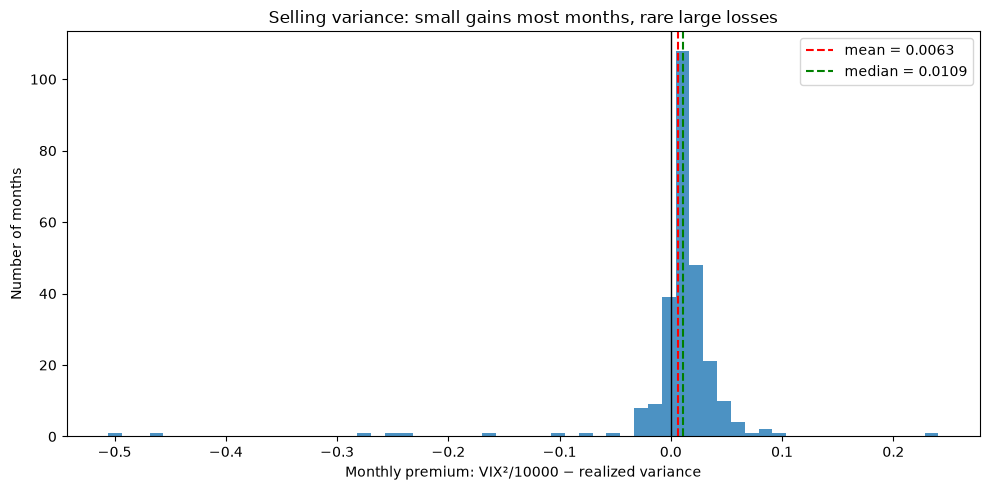

In [5]:
monthly = y.iloc[::21]          # non-overlapping monthly sample
q05 = monthly.quantile(0.05)

summary = pd.Series({
    'months': len(monthly),
    'mean': monthly.mean(),
    'median': monthly.median(),
    'share positive': (monthly > 0).mean(),
    'skewness': monthly.skew(),
    'excess kurtosis': monthly.kurt(),      # 0 = normal
    '5% CVaR': monthly[monthly <= q05].mean(),
    'worst month': monthly.min(),
    'best month': monthly.max(),
})
display(summary.round(4))
print('\n5 worst months (entry date):')
print(monthly.nsmallest(5).round(4))

n_pos = int((monthly > 0).sum())
sign = stats.binomtest(n_pos, len(monthly), 0.5)
print(f"\nSign test: {n_pos}/{len(monthly)} months positive, p = {sign.pvalue:.2e}")
print(f"Normality test (D'Agostino): p = {stats.normaltest(monthly).pvalue:.2e}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(monthly, bins=60, color='tab:blue', alpha=0.8)
ax.axvline(0, color='k', lw=1)
ax.axvline(monthly.mean(), color='red', ls='--', label=f'mean = {monthly.mean():.4f}')
ax.axvline(monthly.median(), color='green', ls='--', label=f'median = {monthly.median():.4f}')
ax.set_xlabel('Monthly premium: VIX²/10000 − realized variance')
ax.set_ylabel('Number of months')
ax.set_title('Selling variance: small gains most months, rare large losses')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/figures/fig2_premium_distribution.png', dpi=150)
plt.show()

## 4. Episode table
For each entry in `EPISODES`: peak VIX, average realized vol, worst `vrp`, and the cumulative short-variance P&L over the episode.

Note on 2022: stocks fell but VIX stayed contained, so it should look much milder than 2008, Feb 2018, 2020 or Apr 2025.

In [6]:
rows = []
for name, (start, end) in EPISODES.items():
    sub = df[episode_mask(df.index, name)]
    rows.append({
        'episode': name,
        'peak VIX': sub['vix'].max(),
        'realized vol (%)': 100 * np.sqrt(sub['rv_d'].mean()),
        'swap sold day 1 (vol pts)': sub['vrp_volpts'].iloc[0],
        'swap sold day 1 (var)': sub['vrp'].iloc[0],
        'worst swap in episode (var)': sub['vrp'].min(),
    })
episodes = pd.DataFrame(rows).set_index('episode').round(3)
display(episodes)


,peak VIX,realized vol (%),swap sold day 1 (vol pts),swap sold day 1 (var),worst swap in episode (var)
episode,,,,,
GFC 2008,80.86,55.911,-32.324,-0.247,-0.565
US downgrade Aug 2011,48.00,37.118,-28.335,-0.180,-0.186
China deval Aug 2015,40.74,27.496,-18.111,-0.080,-0.080
Volmageddon Feb 2018,37.32,25.432,-12.085,-0.048,-0.052
COVID Mar 2020,82.69,67.827,-71.795,-0.722,-0.816
2022 bear (contrast),36.45,24.392,-1.992,-0.007,-0.080
Yen carry Aug 2024,38.57,19.420,-2.914,-0.010,-0.010
Tariff shock Apr 2025,52.33,40.110,-25.918,-0.180,-0.183


## 5. Takeaways for the executive summary
- **Option sellers are usually overpaid.** VIX² exceeded the variance that followed in 82% of months, by 3.5 volatility points on average; a sign test rejects "50/50" overwhelmingly (p ≈ 10⁻²⁷).
- **But it is not a free lunch.** The payoff is extremely left-skewed (skew −5.4, excess kurtosis 42); one month, March 2020, erased about 46 typical months of gains. Once overlapping data is handled properly, the mean premium is only borderline significant (Newey–West t ≈ 2.1–2.3; non-overlapping t ≈ 1.6–2.6).
- **The losses come from sudden crashes, not bear markets.** Selling on the first day of each stress episode lost 32 vol points in 2008 and 72 in COVID, but only 2 in the slow 2022 decline. The premium is payment for bearing crash risk.